**Install & Import Libraries**

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


**Upload & Load Dataset**

In [13]:
from google.colab import files
uploaded = files.upload()  # upload Crop_recommendation.csv

df = pd.read_csv("Crop_recommendation.csv")
print("✅ Dataset Loaded!")
print("Shape:", df.shape)
print(df.head())

Saving Crop_recommendation.csv to Crop_recommendation.csv
✅ Dataset Loaded!
Shape: (2200, 8)
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice


**Explore the Data**

In [14]:
print("Column Names:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())
print("\nCrop Labels:\n", df['label'].unique())
print("\nBasic Statistics:\n", df.describe())

Column Names: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Data Types:
 N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object

Missing Values:
 N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Crop Labels:
 ['rice' 'maize' 'chickpea' 'kidneybeans' 'pigeonpeas' 'mothbeans'
 'mungbean' 'blackgram' 'lentil' 'pomegranate' 'banana' 'mango' 'grapes'
 'watermelon' 'muskmelon' 'apple' 'orange' 'papaya' 'coconut' 'cotton'
 'jute' 'coffee']

Basic Statistics:
                  N            P            K  temperature     humidity  \
count  2200.000000  2200.000000  2200.000000  2200.000000  2200.000000   
mean     50.551818    53.362727    48.149091    25.616244    71.481779   
std      36.917334    32.985883    50.647931     5.0

**Visualize the Data**

/tmp/ipykernel_793/1010299468.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='viridis')


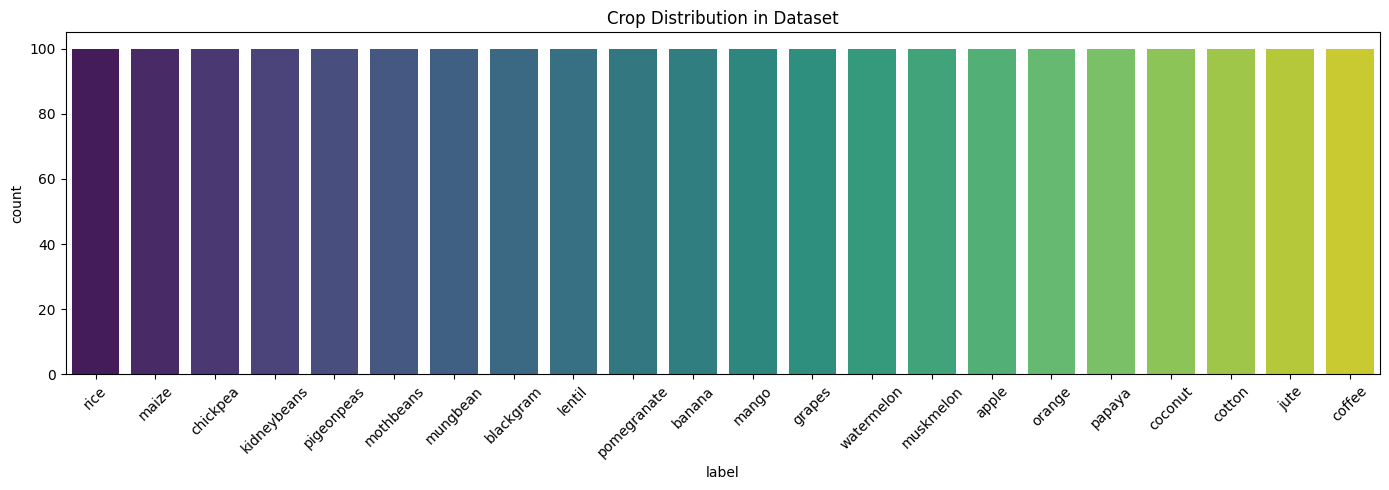

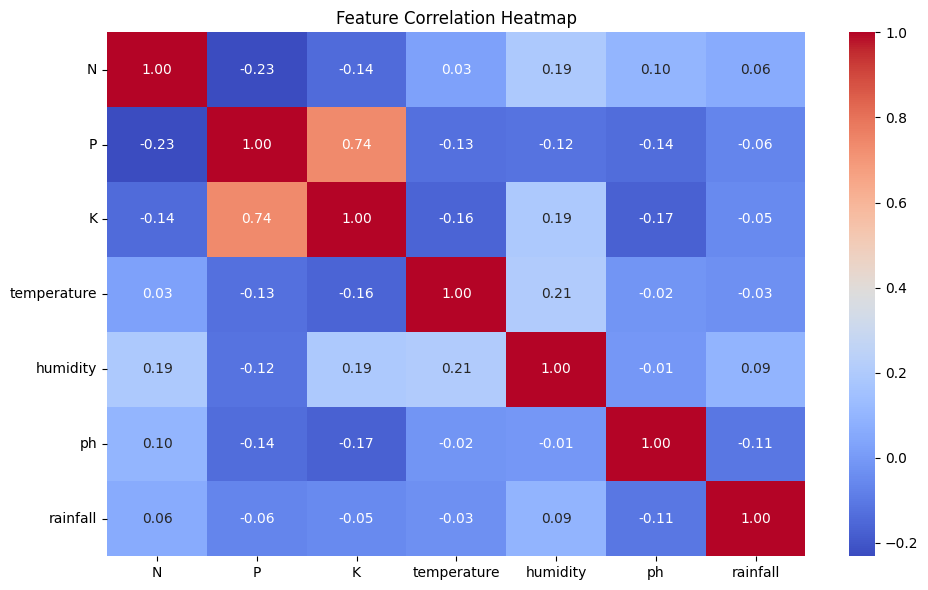

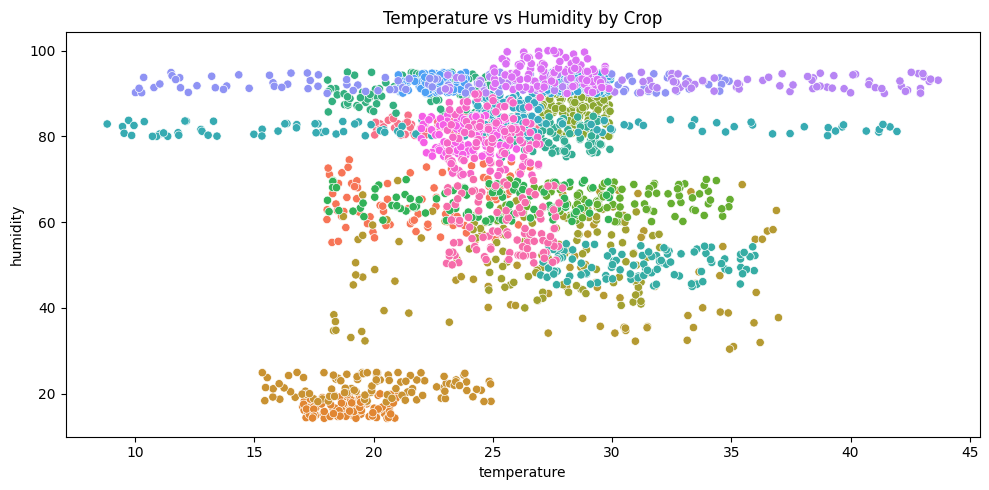

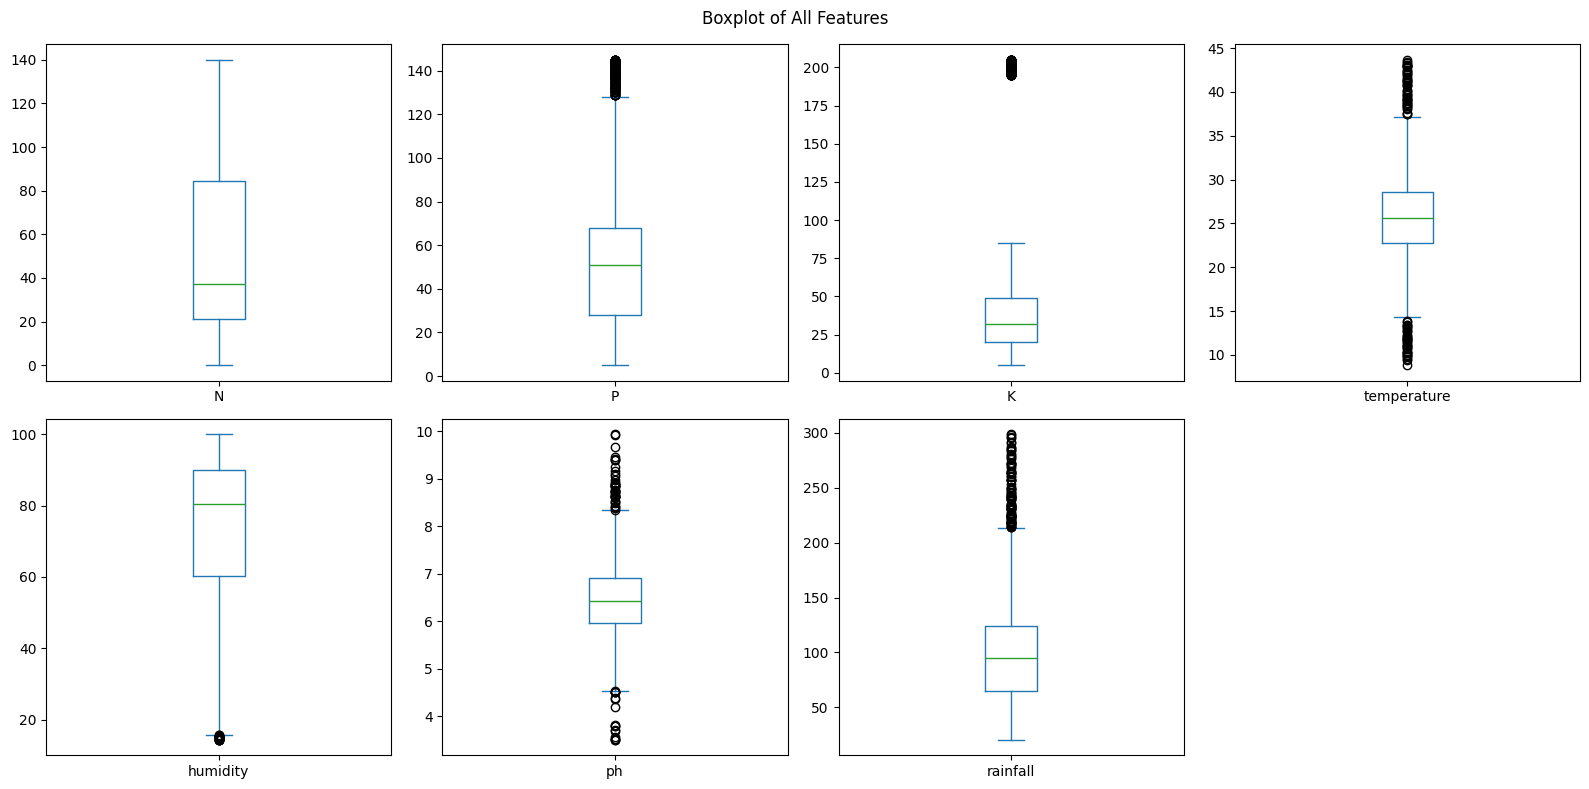

✅ All plots done!


In [15]:
# Plot 1: Crop Distribution
plt.figure(figsize=(14, 5))
sns.countplot(x='label', data=df, palette='viridis')
plt.title('Crop Distribution in Dataset')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot 2: Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df.drop('label', axis=1).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

# Plot 3: Temperature vs Humidity
plt.figure(figsize=(10, 5))
sns.scatterplot(x='temperature', y='humidity', hue='label', data=df, legend=False)
plt.title('Temperature vs Humidity by Crop')
plt.tight_layout()
plt.show()

# Plot 4: Boxplots
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
df[features].plot(kind='box', subplots=True, layout=(2, 4), figsize=(16, 8))
plt.suptitle('Boxplot of All Features')
plt.tight_layout()
plt.show()

print("✅ All plots done!")

**Train the AI Model**

In [8]:
# Prepare Features & Target
X = df.drop('label', axis=1)
y = df['label']

# Encode Labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split Data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42
)

print("✅ Training samples:", X_train.shape[0])
print("✅ Testing samples :", X_test.shape[0])

# Train Random Forest Model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
print("\n✅ Model Training Done!")

# Check Accuracy
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"✅ Model Accuracy: {accuracy * 100:.2f}%")

✅ Training samples: 1760
✅ Testing samples : 440

✅ Model Training Done!
✅ Model Accuracy: 99.32%


 **Evaluate the Model**

Classification Report:

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        23
      banana       1.00      1.00      1.00        21
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        26
     coconut       1.00      1.00      1.00        27
      coffee       1.00      1.00      1.00        17
      cotton       1.00      1.00      1.00        17
      grapes       1.00      1.00      1.00        14
        jute       0.92      1.00      0.96        23
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.92      1.00      0.96        11
       maize       1.00      1.00      1.00        21
       mango       1.00      1.00      1.00        19
   mothbeans       1.00      0.96      0.98        24
    mungbean       1.00      1.00      1.00        19
   muskmelon       1.00      1.00      1.00        17
      orange       1.00      1.00      1.00        14
   

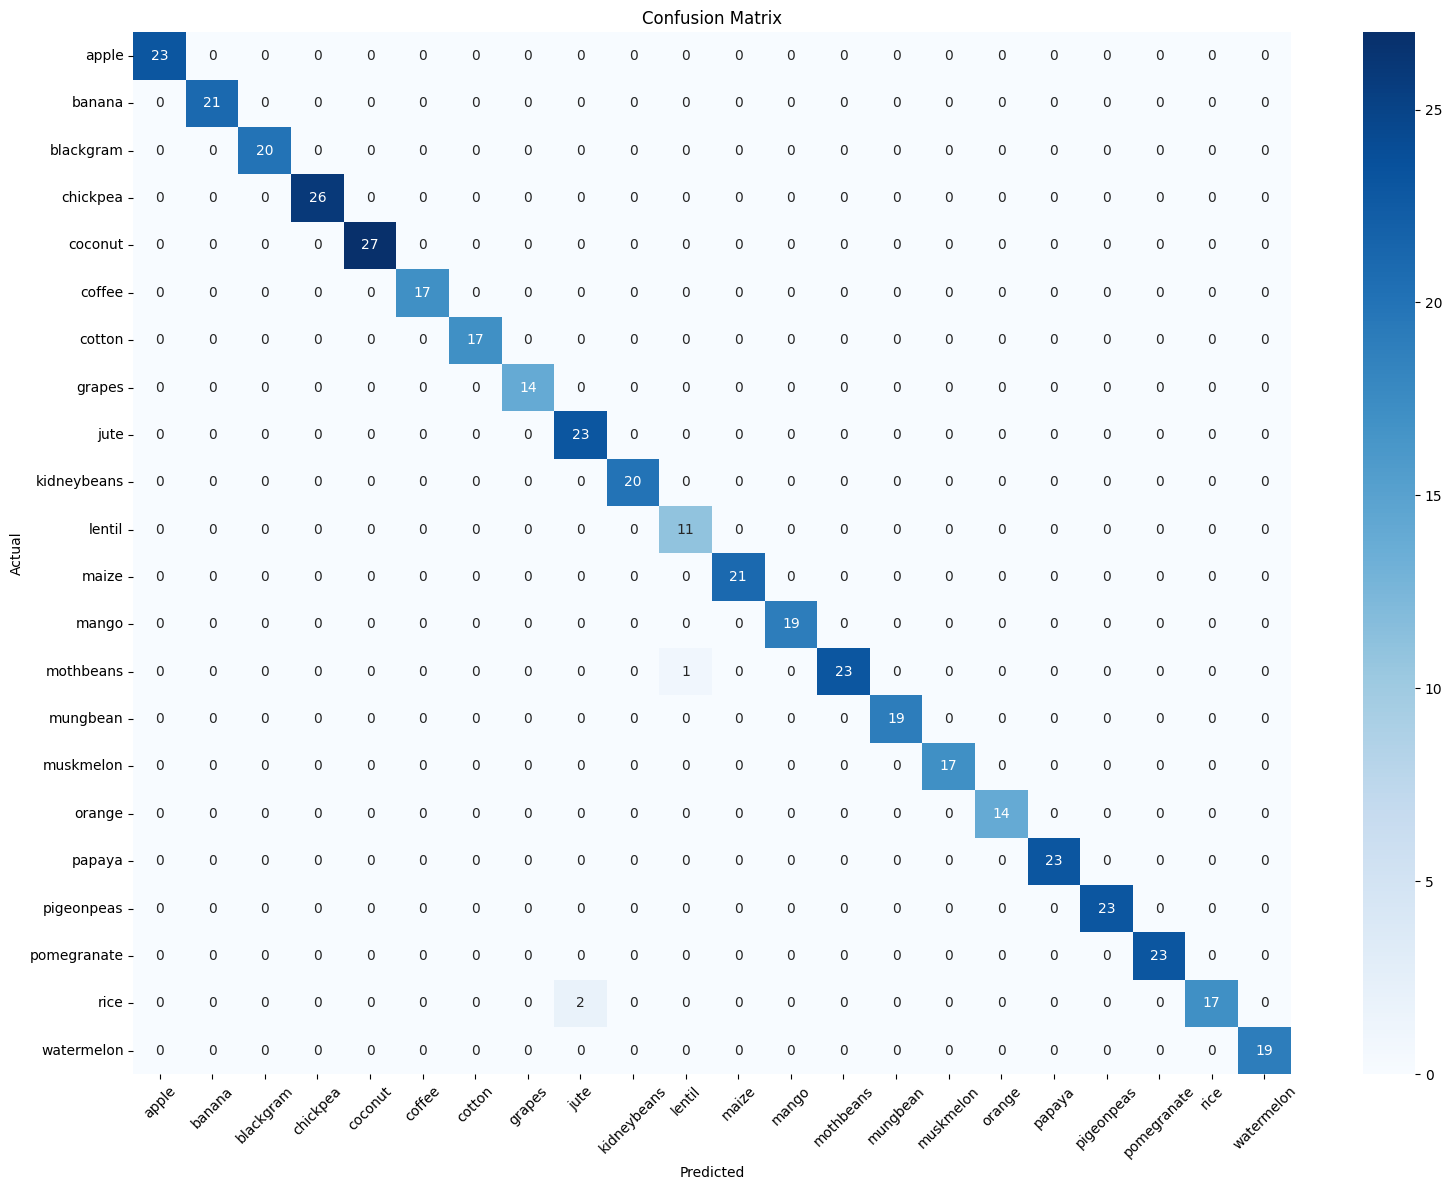

✅ Evaluation Done!


In [16]:
# Classification Report
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Confusion Matrix
plt.figure(figsize=(16, 12))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("✅ Evaluation Done!")

Predict Your Own Crop

In [17]:
# Enter your own soil/weather values
input_data = pd.DataFrame([[90, 42, 43, 20.8, 82.0, 6.5, 202.9]],
              columns=['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall'])

prediction = model.predict(input_data)
crop = le.inverse_transform(prediction)

print(f"🌱 Recommended Crop: {crop[0].upper()}")

🌱 Recommended Crop: RICE


**Save the Model (Optional)**

In [18]:
import joblib

joblib.dump(model, 'crop_model.pkl')
joblib.dump(le, 'label_encoder.pkl')
print("✅ Model saved as crop_model.pkl")

✅ Model saved as crop_model.pkl
